#  Churn Analysis and Customer Intelligence

In [4]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [5]:
 # Excel file path
excel_file = 'customer_churn_data.xlsx'

# Create SQLite database connection
conn = sqlite3.connect('customer_churn.db')

# Read all sheet names from Excel file
excel_data = pd.ExcelFile(excel_file)

# Loop through each sheet and store as separate table
for sheet in excel_data.sheet_names:
    df = pd.read_excel(excel_file, sheet_name=sheet) # Read sheet into dataframe
    # Write dataframe to SQLite table
    df.to_sql(
        name=sheet,          # Table name = Sheet name
        con=conn,
        if_exists='replace', # Replace table if already exists
        index=False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [6]:
# Connect to SQLite database
conn = sqlite3.connect('customer_churn.db')

# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [7]:
df_db_customer.head()

,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,NaN


# Data cleaning


In [8]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  500 non-null    str    
 1   name        500 non-null    str    
 2   country     500 non-null    str    
 3   state       500 non-null    str    
 4   gender      500 non-null    str    
 5   dob         500 non-null    str    
 6   interests   431 non-null    str    
 7   pincode     411 non-null    float64
dtypes: float64(1), str(7)
memory usage: 63.5 KB


In [9]:
# a. rename col - name to customer_name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender

In [10]:
# a. rename col - name to customer_name
df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)


In [11]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,NaN
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,NaN
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,NaN
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,NaN
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,NaN


In [12]:
# b. drop columns - interest and pincode
df_db_customer.drop(columns = ['interests', 'pincode'],inplace = True)

In [13]:
df_db_customer.head()

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00


In [14]:
# c. change data type - dob
df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [15]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     500 non-null    str           
 1   customer_name  500 non-null    str           
 2   country        500 non-null    str           
 3   state          500 non-null    str           
 4   gender         500 non-null    str           
 5   dob            500 non-null    datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 43.6 KB


In [16]:
# d. data standardization - gender
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})

In [17]:
df_db_customer['gender'].unique()

<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

In [18]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               500 non-null    str    
 1   subscription_start_date  500 non-null    str    
 2   subscription_type        500 non-null    str    
 3   renewal_date             500 non-null    str    
 4   plan_type                500 non-null    str    
 5   contract_type            500 non-null    str    
 6   cancellation_date        125 non-null    str    
 7   cancellation_reason      125 non-null    str    
 8   monthly_charges          500 non-null    float64
 9   cltv                     500 non-null    int64  
 10  churn_score              500 non-null    int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 82.7 KB


In [19]:
# change data type to date - subscription_start_date , renewal_date, cancellation_date
date_col = ['subscription_start_date' , 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)


In [20]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               500 non-null    str           
 1   subscription_start_date  500 non-null    datetime64[us]
 2   subscription_type        500 non-null    str           
 3   renewal_date             500 non-null    datetime64[us]
 4   plan_type                500 non-null    str           
 5   contract_type            500 non-null    str           
 6   cancellation_date        125 non-null    datetime64[us]
 7   cancellation_reason      125 non-null    str           
 8   monthly_charges          500 non-null    float64       
 9   cltv                     500 non-null    int64         
 10  churn_score              500 non-null    int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 61.8 KB


In [21]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0002-ORFBO,2025-11-12 00:00:00,Y,31,None,plan change request
1,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
2,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
3,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
4,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew


In [22]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      230 non-null    str   
 1   complaint_date  230 non-null    str   
 2   escalations     230 non-null    str   
 3   csat_score      230 non-null    int64 
 4   col_1           0 non-null      object
 5   comment         225 non-null    str   
dtypes: int64(1), object(1), str(4)
memory usage: 21.3+ KB


In [23]:
df_db_support.drop(columns = ['col_1','comment'],inplace = True)

In [24]:
# change data type to date - complaint_date
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 230 entries, 0 to 229
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      230 non-null    str           
 1   complaint_date  230 non-null    datetime64[us]
 2   escalations     230 non-null    str           
 3   csat_score      230 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 10.0 KB


# feature engineering

In [25]:
# Create a new column

In [26]:
# create a new col using existing col - churn flag

# Customer is churned if cancellation_date is not null
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0)
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


Merge data frames

In [27]:
df_db_subscription.shape

(500, 12)

In [28]:
df.shape

(230, 4)

In [29]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0002-ORFBO,2025-11-12,Y,31
1,0003-MKNFE,2024-08-28,N,60
2,0003-MKNFE,2024-08-28,Y,10
3,0013-EXCHZ,2024-01-20,Y,20
4,0013-MHZWF,2025-03-18,N,90
...,...,...,...,...
225,96742-LVGSM,2026-05-15,N,91
226,97825-LEHBP,2026-05-10,N,77
227,98888-AEBPA,2025-05-06,N,57
228,99098-ZUJKQ,2025-01-18,N,90


In [30]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [31]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [32]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,complaint_count
173,76766-XKVCG,2023-01-01,N,11,1
64,19141-TKUNP,2023-01-28,Y,100,1
208,90474-MSJZU,2023-02-04,N,91,1
97,39467-NHBBB,2023-02-08,N,89,1
52,13666-PHLMV,2023-02-19,N,93,1


In [33]:
df = (df_db_subscription
                    .merge(df_db_customer, on = 'customerid', how = 'left')
                    .merge(df_db_support, on = 'customerid', how = 'left') )

In [34]:
df.shape

(500, 21)

In [35]:
# Export dataframe

In [36]:
df.to_csv('exported_churn_data.csv', index=False)

# Data analysis

In [37]:
# 1. churn rate
churn_rate = df['churn_flag'].mean()*100
print(f"Churn rate :- {churn_rate}%")

Churn rate :- 25.0%


In [38]:
# Retantion rate
Retantion_rate = 100 - churn_rate
print(f"Retantion rate:- {Retantion_rate} %")

Retantion rate:- 75.0 %


In [39]:
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name = ('churn_by_plan')))
churn_by_plan

,plan_type,churn_by_plan
0,Basic,25.84
1,Premium,25.56
2,Standard,23.81


In [40]:
# 4 a. Churn by state
churn_by_state = (df.groupby('state')['churn_flag'].mean().mul(100).round(2).reset_index(name = ('churn_by_state')))
churn_by_state

,state,churn_by_state
0,Bihar,22.45
1,Delhi,20.51
2,Gujarat,23.40
3,Karnataka,22.22
4,Kathmandu,0.00
5,Kerala,33.33
6,Madhya Pradesh,29.73
7,Maharashtra,33.33
8,Meghalaya,66.67
9,Nagaland,0.00


In [41]:
# 5. ARPU - Avg Revenue per user
arpu = df['monthly_charges'].mean().round(2)
print('ARPU = ', arpu)

ARPU =  25.47


In [42]:
# 6. Avg Customer Tenure
today = pd.Timestamp.today()

df['tanure_days'] = np.where(
             df['cancellation_date'].notna(),

     (df['cancellation_date'] - df['subscription_start_date']).dt.days,

    (today - df['subscription_start_date']).dt.days
)

avg_tanure = df['tanure_days'].mean().round(0)
print('avg_tanure(Days) = ',avg_tanure)

    

avg_tanure(Days) =  1353.0


In [43]:
# 7. Revenue at risk - revenue lost from churned users
revanue_at_risk = df.loc[df['churn_flag']==1,'monthly_charges'].sum().round(2)
                                                                              
print('Revanue at risk(Rs k ) = ', revanue_at_risk)

Revanue at risk(Rs k ) =  3005.88


In [44]:
# 8. Esclation Rate
esclation_rate = (df['escalations']=='Y').mean()*100
print("Esclation Rate = ",round(esclation_rate),"%")

Esclation Rate =  7 %


In [45]:
# 9. Avg Complaint Per User'
avg_complaints = (df['complaint_count'].sum() / df['complaint_count'].nunique()).round(2)
print('Avgrage complaint per user = ' , avg_complaints)

Avgrage complaint per user =  76.67


In [46]:
# 10. Create a column using existing col - Churn risk
conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70)
]

choices = ['low', 'med', 'high']

df['churn_risk'] = np.select(conditions, choices, default='unkown')

# Visualization using Matplotlib

In [47]:
df_visual = df.copy()

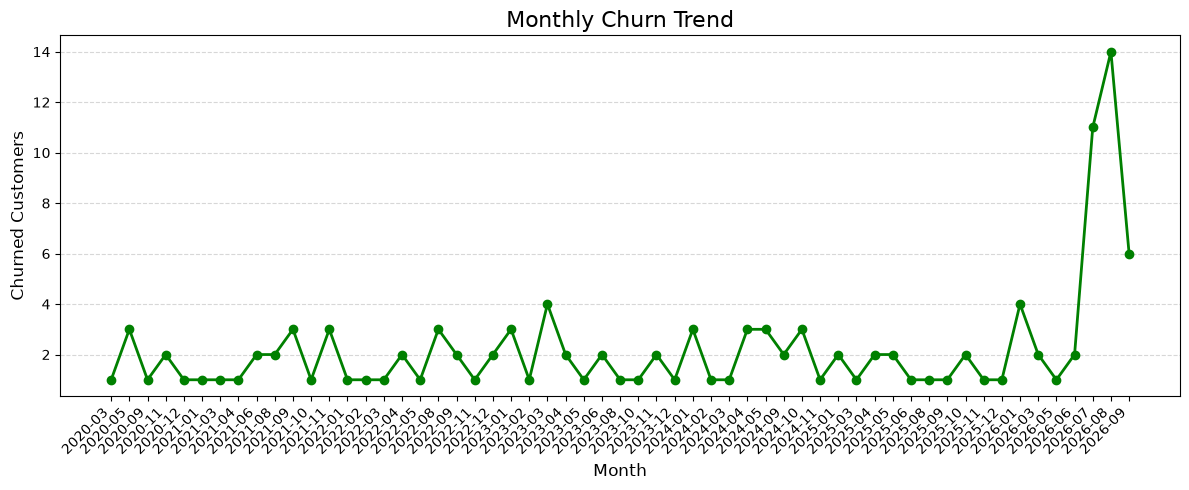

In [48]:
# 1 Monthly Churn Trend (Time Series KPI)


# Convert cancellation date into month
df_visual['cancellation_date'] = pd.to_datetime(
    df_visual['cancellation_date'], errors='coerce'
)

df_visual['cancellation_month'] = (
    df_visual['cancellation_date'].dt.to_period('M')
)

# Filter churned customers and count month-wise
churn_trend = (
    df_visual[df_visual['churn_flag'] == 1]
    .dropna(subset=['cancellation_month'])
    .groupby('cancellation_month')
    .size()
    .sort_index()
)

# Plot the chart
plt.figure(figsize=(12, 5))

plt.plot(
    churn_trend.index.astype(str),
    churn_trend.values,
    color='green',
    marker='o',
    linestyle='-',
    linewidth=2,
    markersize=6
)

plt.title('Monthly Churn Trend', fontsize=16)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Churned Customers', fontsize=12)

plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


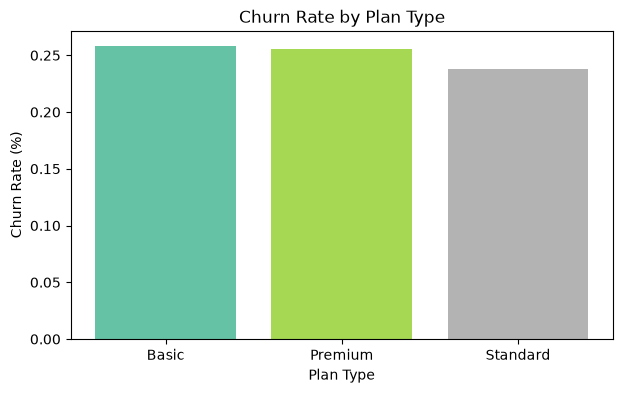

In [49]:
# 4.2 Churn Rate by Plan type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

# colors = ['yellow', 'purple', 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(7,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate (%)')
plt.show()

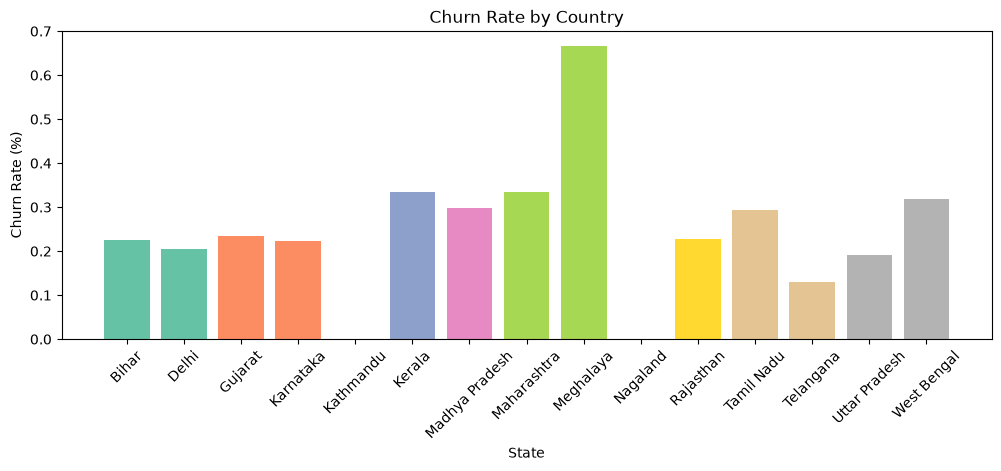

In [50]:
# 4.3 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))

plt.figure(figsize=(12,4))
plt.bar(churn_plan.index, churn_plan.values, color = colors)

plt.title('Churn Rate by Country')
plt.xlabel('State')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45)
plt.show()

# Visulaization using Seaborn

In [51]:
# Heatmap (Correlation Matrix)

In [52]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,Y
1,Premium,Annual,91,1,high,Y
2,Basic,Monthly,34,0,low,NaN
3,Premium,Annual,8,0,low,NaN
4,Standard,Monthly,88,1,high,Y


In [53]:
import warnings
warnings.filterwarnings("ignore")

In [54]:
# Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']]

order_mappings = {
    'plan_type' : ['Basic', 'Standard', 'Premium'],
    'contract_type' : ['Monthly', 'Annual'],
    'churn_risk': ['low', 'med', 'high']
    }

for col, order in order_mappings.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'), categories=order, ordered=True).codes

In [55]:
df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_flag', 'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,Y
1,Premium,Annual,91,1,high,Y
2,Basic,Monthly,34,0,low,NaN
3,Premium,Annual,8,0,low,NaN
4,Standard,Monthly,88,1,high,Y


In [56]:
df_encoded.head()
df_encoded['escalations'] = df_encoded['escalations'].map({
    'Y': 1,
    'N': 0
})

<Axes: >

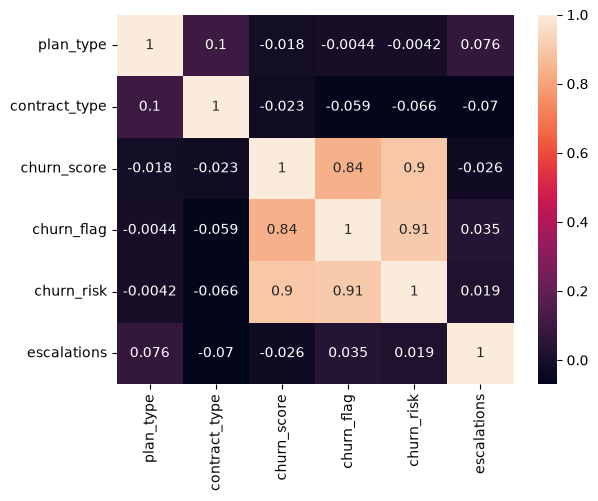

In [57]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot=True)

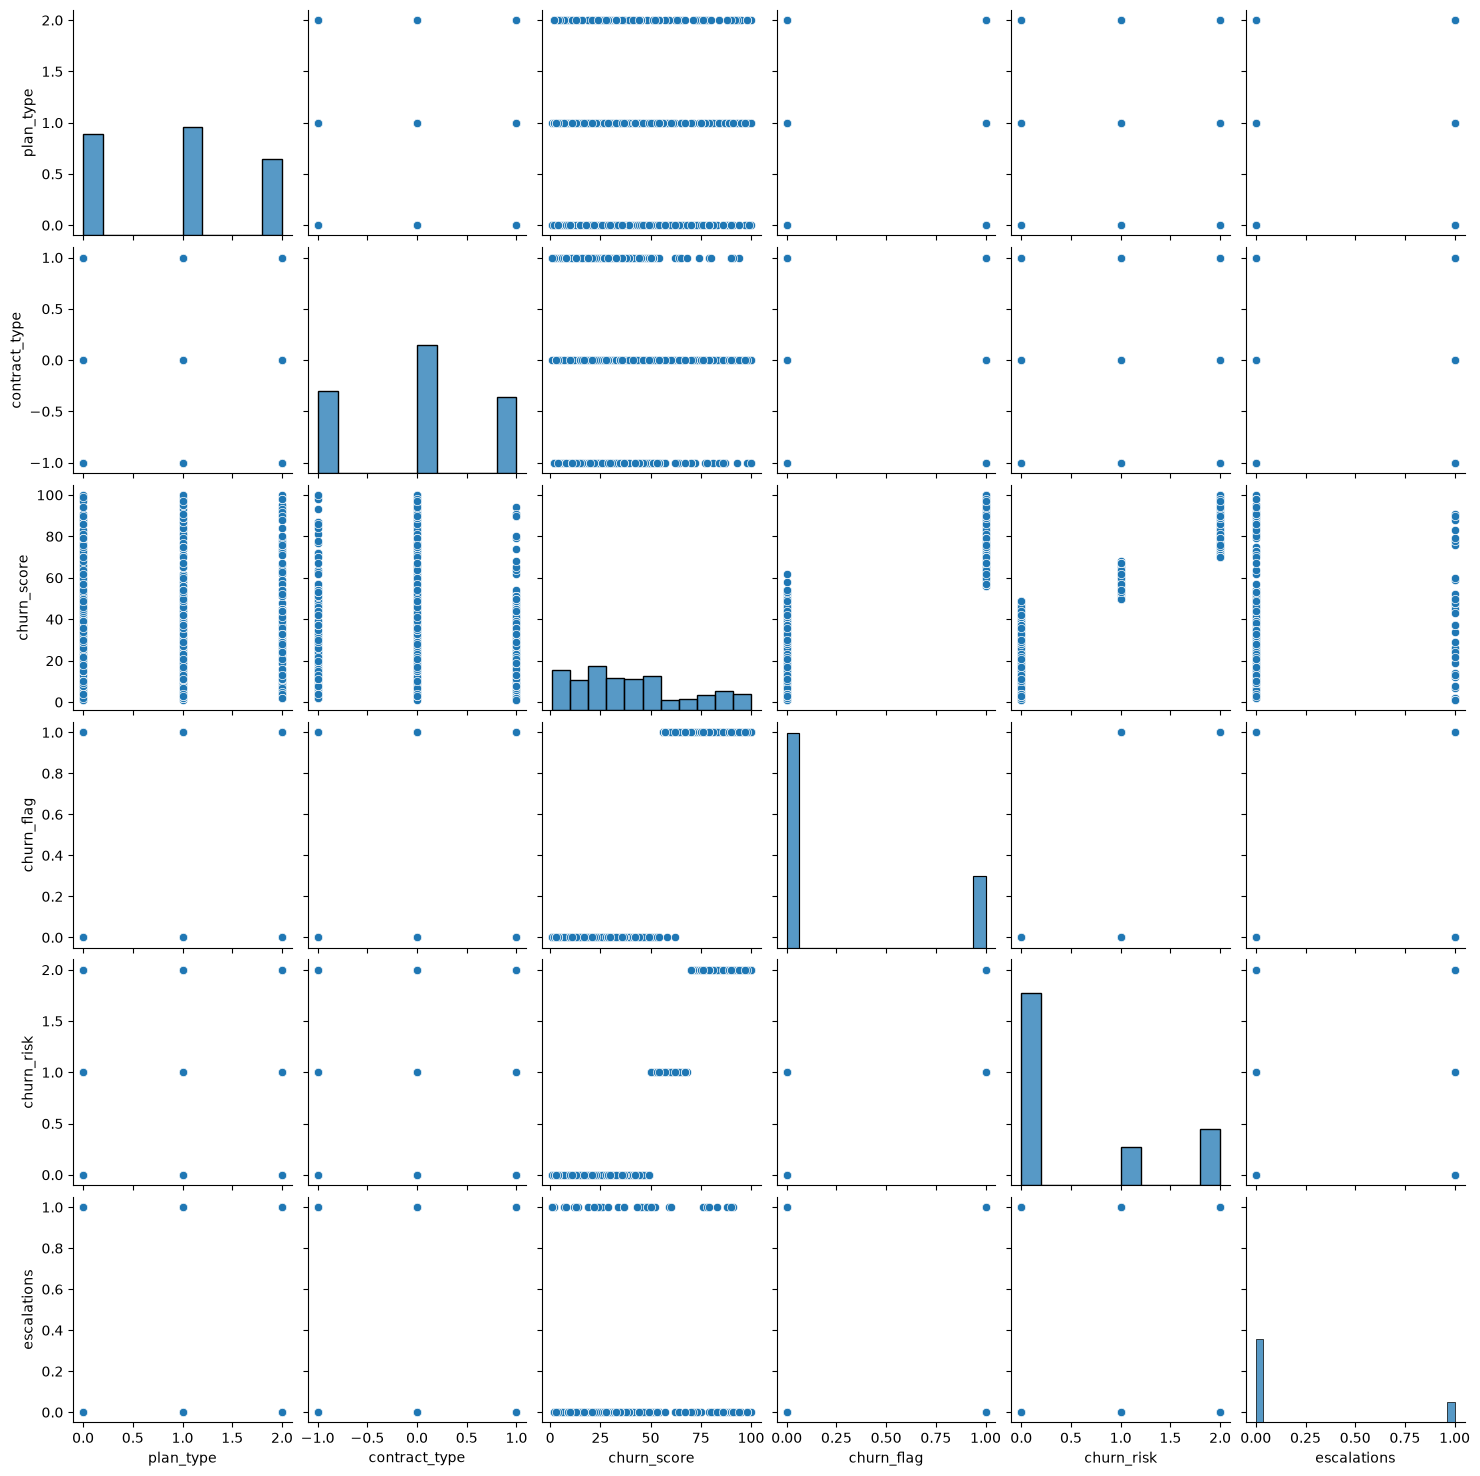

In [58]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

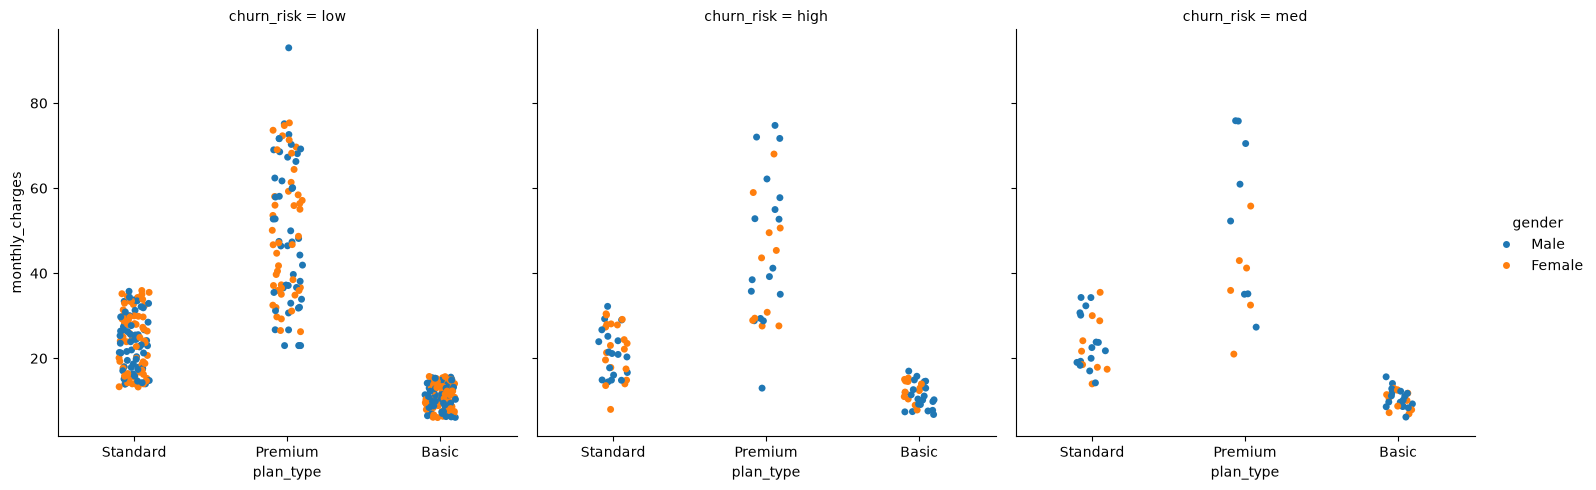

In [59]:
# catplt/Facegrid plot - multi-dim comparison

sns.catplot(data=df_visual,
    x='plan_type',
    y='monthly_charges',
    hue='gender',
    col='churn_risk')

# Pivot table

In [60]:
# Pivot Table

pd.pivot_table(
    df_visual,
    index='plan_type',
    values='churn_flag',
    aggfunc = 'mean'
)

,churn_flag
plan_type,
Basic,0.258427
Premium,0.255639
Standard,0.238095


In [61]:
# pivot table using multiple cols and agg type

pd.pivot_table(
    df_visual,
    index='plan_type',
    values=['monthly_charges', 'customerid', 'churn_flag'],
    aggfunc = {
        'monthly_charges' : 'sum',
        'customerid' : 'nunique',
        'churn_flag' : 'mean'
    }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.258427,178,1963.21
Premium,0.255639,133,6361.25
Standard,0.238095,189,4412.86


# completed